# Advanced Machine Learning Mini Project: Ensemble Methods (Bagging, Random Forest, Boosting)

**Subject:** Machine Learning (METCE11504) &nbsp;|&nbsp; **Activity:** ALA 3  
**Student:** ____________________ &nbsp; **Enrollment No.:** ____________

## 1. Problem formulation
**Task:** recognise handwritten digits (0–9) from small **8 × 8 grey-scale images** (64 pixel features) — a 10-class classification problem.  
**Data:** *Digits* dataset (UCI optical recognition of handwritten digits; included in scikit-learn): **1,797 images**, about 180 per class.  
**Why this problem:** low-resolution images are typical of cheap sensors and embedded devices (an IoT-style setting, e.g. reading digits on a meter), where a compact and accurate classifier is needed.  
**Concept studied:** *ensemble learning* — combining many weak/unstable learners to obtain a better one.

| Method | Idea | Effect on error |
|---|---|---|
| **Bagging** | train many trees on bootstrap samples, average their votes | reduces **variance** |
| **Random Forest** | bagging + random subset of features at each split (de-correlates the trees) | reduces variance further |
| **AdaBoost** | trees trained one after another, each focusing on previously misclassified samples | reduces **bias** |
| **Gradient Boosting** | each new tree fits the errors (gradient) of the current ensemble | reduces bias, strong accuracy |

**Objectives:** (1) compare a single decision tree with the four ensembles, (2) measure **bias and variance** empirically, (3) study the effect of the number of estimators and tuning, (4) analyse performance, cost and errors, (5) discuss future scope.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RS = 42

## 2. Data and preprocessing

Images: 1797 | Pixels (features): 64 | Classes: 10 | Pixel range: 0.0 - 16.0 | Missing: 0
Images per class: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


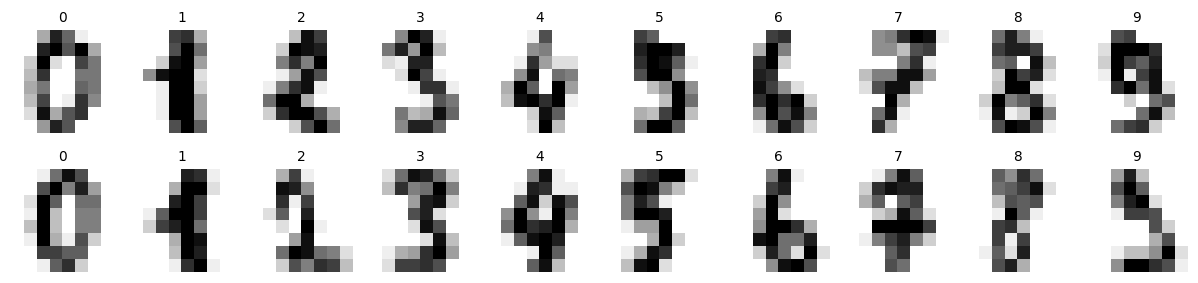

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Images:", X.shape[0], "| Pixels (features):", X.shape[1], "| Classes:", len(np.unique(y)), "| Pixel range:", X.min(), "-", X.max(), "| Missing:", int(np.isnan(X).sum()))
print("Images per class:", np.bincount(y).tolist())
fig, ax = plt.subplots(2, 10, figsize=(11, 2.8))
for i, a in enumerate(ax.ravel()):
    a.imshow(digits.images[i], cmap="gray_r"); a.set_title(str(y[i]), fontsize=9); a.axis("off")
plt.tight_layout()

In [3]:
# Stratified split; tree-based models need no feature scaling (they are invariant to monotone transformations)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1347, 64) | Test: (450, 64)


## 3. Models and comparison

In [4]:
models = {
    "Decision Tree (single)":      DecisionTreeClassifier(random_state=RS),
    "Bagging (100 trees)":         BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=RS),
    "Random Forest (300 trees)":   RandomForestClassifier(n_estimators=300, random_state=RS),
    "AdaBoost (200 stumps-depth3)": AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=200, learning_rate=0.5, random_state=RS),
    "Gradient Boosting (100 trees)": GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=RS),
    "SVM (RBF) - non-ensemble reference": SVC(gamma="scale", C=10),
}
def n_nodes(m):
    est = getattr(m, "estimators_", None)
    if est is None: return m.tree_.node_count if hasattr(m, "tree_") else np.nan
    return int(sum(t.tree_.node_count for t in np.ravel(est)))
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
rows, fitted = [], {}
for name, m in models.items():
    cvs = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy")
    t0 = time.perf_counter(); m.fit(X_train, y_train); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = m.predict(X_test); t_pred = (time.perf_counter() - t0) / len(X_test) * 1000
    fitted[name] = m
    rows.append([name, cvs.mean(), cvs.std(), accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"), t_fit, t_pred, n_nodes(m)])
res = pd.DataFrame(rows, columns=["model", "cv_acc_mean", "cv_acc_sd", "test_accuracy", "test_macro_f1", "train_time_s", "predict_ms_per_image", "tree_nodes"]).set_index("model")
res.round(4)

                                    cv_acc_mean  cv_acc_sd  test_accuracy  test_macro_f1  train_time_s  predict_ms_per_image  tree_nodes
model                                                                                                                                   
Decision Tree (single)                   0.8485     0.0144         0.8244         0.8228        0.0155                0.0006       265.0
Bagging (100 trees)                      0.9428     0.0037         0.9244         0.9234        1.0683                0.0482     19494.0
Random Forest (300 trees)                0.9770     0.0109         0.9689         0.9683        0.8494                0.0751     97572.0
AdaBoost (200 stumps-depth3)             0.9495     0.0050         0.9511         0.9512        1.4281                0.0553      2994.0
Gradient Boosting (100 trees)            0.9614     0.0134         0.9578         0.9577        6.0982                0.0212     14862.0
SVM (RBF) - non-ensemble reference       

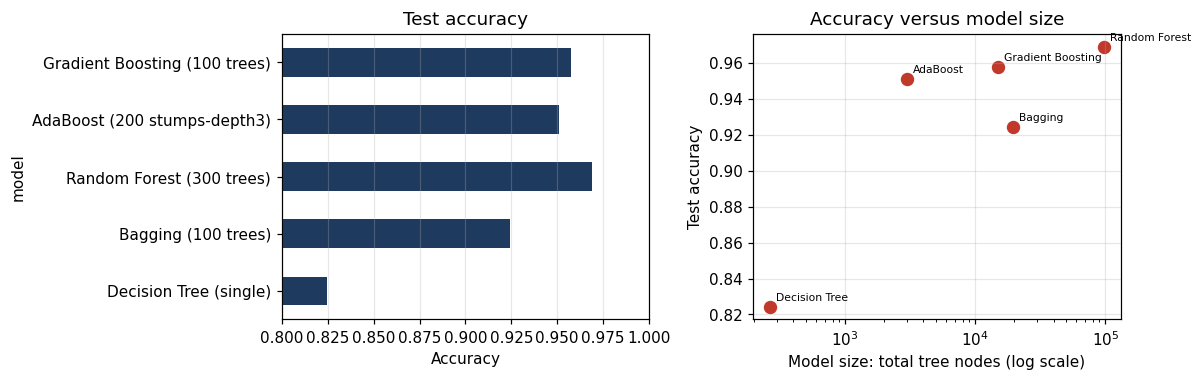

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
r = res.drop(index="SVM (RBF) - non-ensemble reference")
r.test_accuracy.plot.barh(ax=ax[0], color="#1F3A5F", xerr=None); ax[0].set_xlim(0.80, 1.0); ax[0].set_title("Test accuracy"); ax[0].set_xlabel("Accuracy"); ax[0].grid(alpha=.3, axis="x")
ax[1].scatter(r.tree_nodes, r.test_accuracy, s=60, color="#C0392B")
for n, row in r.iterrows(): ax[1].annotate(n.split(" (")[0], (row.tree_nodes, row.test_accuracy), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("Model size: total tree nodes (log scale)"); ax[1].set_ylabel("Test accuracy"); ax[1].set_title("Accuracy versus model size"); ax[1].grid(alpha=.3)
plt.tight_layout()

## 4. Effect of the number of estimators

Trees needed to reach 95% test accuracy: Random Forest = 25, Bagging = >200


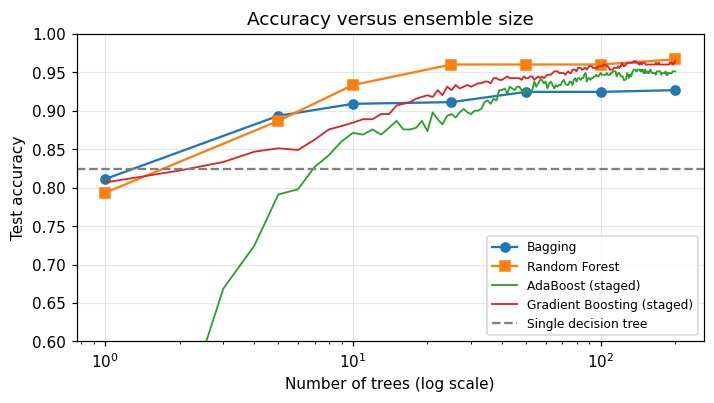

In [6]:
sizes = [1, 5, 10, 25, 50, 100, 200]
curve = {"Bagging": [], "Random Forest": []}
for n in sizes:
    curve["Bagging"].append(accuracy_score(y_test, BaggingClassifier(DecisionTreeClassifier(), n_estimators=n, random_state=RS).fit(X_train, y_train).predict(X_test)))
    curve["Random Forest"].append(accuracy_score(y_test, RandomForestClassifier(n_estimators=n, random_state=RS).fit(X_train, y_train).predict(X_test)))
ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=200, learning_rate=0.5, random_state=RS).fit(X_train, y_train)
gb = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=RS).fit(X_train, y_train)
ada_st = [accuracy_score(y_test, p) for p in ada.staged_predict(X_test)]
gb_st = [accuracy_score(y_test, p) for p in gb.staged_predict(X_test)]
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.plot(sizes, curve["Bagging"], "o-", label="Bagging"); ax.plot(sizes, curve["Random Forest"], "s-", label="Random Forest")
ax.plot(range(1, 201), ada_st, label="AdaBoost (staged)", lw=1.2); ax.plot(range(1, 201), gb_st, label="Gradient Boosting (staged)", lw=1.2)
ax.axhline(res.loc["Decision Tree (single)", "test_accuracy"], color="grey", ls="--", label="Single decision tree")
ax.set_xscale("log"); ax.set_xlabel("Number of trees (log scale)"); ax.set_ylabel("Test accuracy"); ax.set_ylim(0.6, 1.0); ax.set_title("Accuracy versus ensemble size"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout()
print("Trees needed to reach 95%% test accuracy: Random Forest = %s, Bagging = %s" % (next((s for s, a in zip(sizes, curve["Random Forest"]) if a >= .95), ">200"), next((s for s, a in zip(sizes, curve["Bagging"]) if a >= .95), ">200")))

In [7]:
# Random Forest: out-of-bag (OOB) estimate = free validation score from samples left out of each bootstrap
rf_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=RS).fit(X_train, y_train)
print(f"OOB accuracy = {rf_oob.oob_score_:.4f}  |  test accuracy = {accuracy_score(y_test, rf_oob.predict(X_test)):.4f}")

OOB accuracy = 0.9762  |  test accuracy = 0.9689


## 5. Hyper-parameter tuning of the Random Forest (5-fold CV on the training set)

In [8]:
grid = {"max_features": ["sqrt", "log2", 0.5], "min_samples_leaf": [1, 2, 4], "max_depth": [None, 12]}
gs = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=RS), grid, cv=cv, scoring="accuracy").fit(X_train, y_train)
print("Best parameters:", gs.best_params_, "| CV accuracy: %.4f" % gs.best_score_)
rf_tuned = gs.best_estimator_
print("Test accuracy with tuned parameters: %.4f (default Random Forest: %.4f)" % (accuracy_score(y_test, rf_tuned.predict(X_test)), res.loc["Random Forest (300 trees)", "test_accuracy"]))
pd.DataFrame(gs.cv_results_)[["param_max_features", "param_min_samples_leaf", "param_max_depth", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(5).round(4)

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1} | CV accuracy: 0.9785
Test accuracy with tuned parameters: 0.9667 (default Random Forest: 0.9689)


   param_max_features  param_min_samples_leaf param_max_depth  mean_test_score
0                sqrt                       1            None           0.9785
9                sqrt                       1              12           0.9755
3                log2                       1            None           0.9740
12               log2                       1              12           0.9733
1                sqrt                       2            None           0.9725

## 6. Bias–variance analysis (empirical)
To see *why* ensembles help, each method is trained on **B = 20 different random 80% subsets** of the training data and evaluated on the same test images (0-1 loss):  
* **main prediction** for an image = the most frequent prediction over the B models;  
* **bias** = share of test images for which the main prediction is wrong (systematic error);  
* **variance** = average share of models that disagree with the main prediction (instability);  
* **average error** = average share of wrong predictions over the B models.  
(This is a simplified decomposition for 0-1 loss; bias and variance do not add up exactly to the error.)

In [9]:
B = 20
rng = np.random.default_rng(RS)
subsets = [rng.choice(len(X_train), int(.8 * len(X_train)), replace=False) for _ in range(B)]
bv_models = {"Decision Tree": lambda: DecisionTreeClassifier(random_state=RS),
             "Bagging (25)": lambda: BaggingClassifier(DecisionTreeClassifier(), n_estimators=25, random_state=RS),
             "Random Forest (100)": lambda: RandomForestClassifier(n_estimators=100, random_state=RS),
             "AdaBoost (100)": lambda: AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=100, learning_rate=0.5, random_state=RS),
             "Gradient Boosting (50)": lambda: GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=RS)}
rows = []
for name, mk in bv_models.items():
    P = np.array([mk().fit(X_train[s], y_train[s]).predict(X_test) for s in subsets])        # B x n_test predictions
    main = np.apply_along_axis(lambda c: np.bincount(c, minlength=10).argmax(), 0, P)
    rows.append([name, (main != y_test).mean(), (P != main).mean(), (P != y_test).mean()])
bv = pd.DataFrame(rows, columns=["model", "bias", "variance", "avg_error"]).set_index("model")
bv.round(4)

                          bias  variance  avg_error
model                                              
Decision Tree           0.1089    0.1307     0.1752
Bagging (25)            0.0689    0.0392     0.0860
Random Forest (100)     0.0333    0.0097     0.0353
AdaBoost (100)          0.0489    0.0327     0.0651
Gradient Boosting (50)  0.0556    0.0326     0.0652

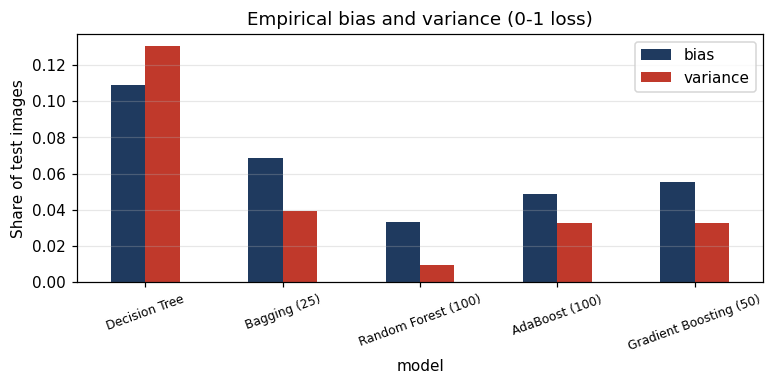

In [10]:
ax = bv[["bias", "variance"]].plot.bar(figsize=(7.2, 3.6), color=["#1F3A5F", "#C0392B"])
ax.set_ylabel("Share of test images"); ax.set_title("Empirical bias and variance (0-1 loss)"); ax.tick_params(axis="x", labelrotation=20, labelsize=8); ax.grid(alpha=.3, axis="y")
plt.tight_layout()

## 7. Error analysis and feature importance of the best model

Best ensemble: Random Forest (300 trees) | test accuracy = 0.9689 | errors: 14 of 450 images
F1 per digit: {0: 0.977, 1: 0.957, 2: 1.0, 3: 0.979, 4: 0.978, 5: 0.978, 6: 0.989, 7: 0.968, 8: 0.902, 9: 0.955}


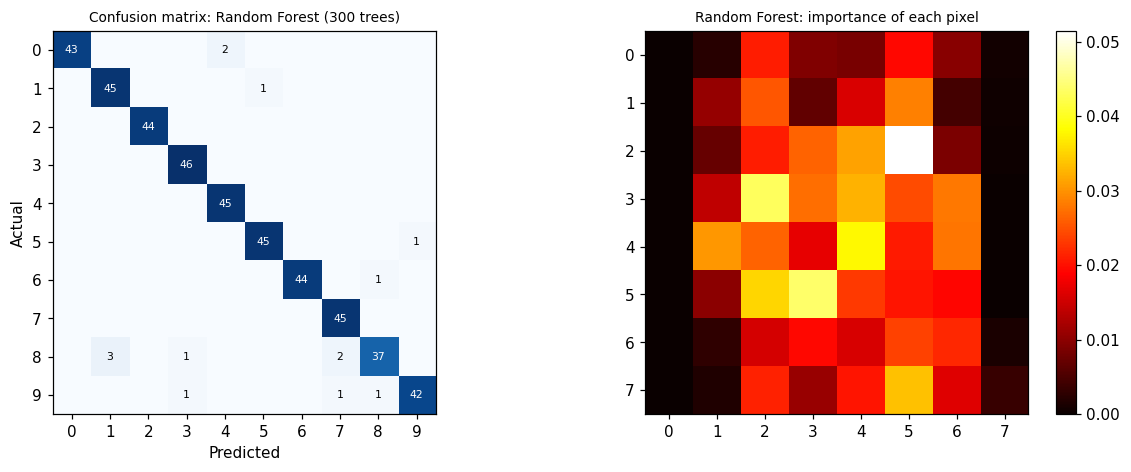

In [11]:
best_name = res.drop(index="SVM (RBF) - non-ensemble reference").test_accuracy.idxmax()
bm = fitted[best_name]
pred = bm.predict(X_test)
cm = confusion_matrix(y_test, pred)
print("Best ensemble:", best_name, "| test accuracy = %.4f | errors: %d of %d images" % (accuracy_score(y_test, pred), (pred != y_test).sum(), len(y_test)))
per_class = pd.Series(f1_score(y_test, pred, average=None), index=range(10)).round(3)
print("F1 per digit:", per_class.to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_title(f"Confusion matrix: {best_name}", fontsize=9); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
for i in range(10):
    for j in range(10):
        if cm[i, j]: ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
imp = RandomForestClassifier(n_estimators=300, random_state=RS).fit(X_train, y_train).feature_importances_.reshape(8, 8)
im = ax[1].imshow(imp, cmap="hot"); ax[1].set_title("Random Forest: importance of each pixel", fontsize=9); plt.colorbar(im, ax=ax[1], fraction=.046)
plt.tight_layout()

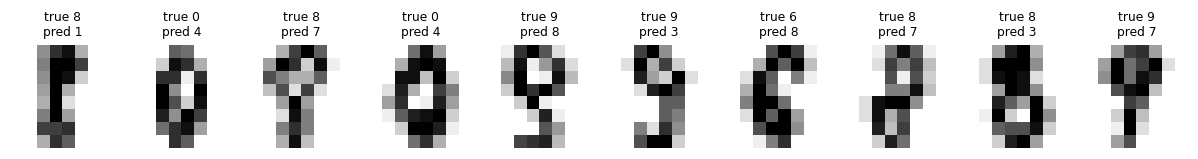

In [12]:
wrong = np.where(pred != y_test)[0]
fig, ax = plt.subplots(1, min(10, len(wrong)), figsize=(11, 1.9))
for a, i in zip(np.atleast_1d(ax), wrong[:10]):
    a.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); a.set_title(f"true {y_test[i]}\npred {pred[i]}", fontsize=8); a.axis("off")
plt.tight_layout()

In [13]:
pairs = sorted(((int(cm[i, j]), i, j) for i in range(10) for j in range(10) if i != j and cm[i, j]), reverse=True)[:5]
print("Most frequent confusions (count, true -> predicted):", [(c, f"{i}->{j}") for c, i, j in pairs])
corners = [imp[0, 0], imp[0, 7], imp[7, 0], imp[7, 7]]
print("Importance of the four corner pixels:", np.round(corners, 5), "| mean importance over all 64 pixels:", round(float(imp.mean()), 4))

Most frequent confusions (count, true -> predicted): [(3, '8->1'), (2, '8->7'), (2, '0->4'), (1, '9->8'), (1, '9->7')]
Importance of the four corner pixels: [0.00e+00 7.40e-04 2.00e-05 3.51e-03] | mean importance over all 64 pixels: 0.0156


In [14]:
SUMMARY = dict(n=int(X.shape[0]), p=int(X.shape[1]), n_train=len(X_train), n_test=len(X_test), best=best_name,
               best_acc=float(accuracy_score(y_test, pred)), errors=int((pred != y_test).sum()), oob=float(rf_oob.oob_score_),
               rf_tuned=float(accuracy_score(y_test, rf_tuned.predict(X_test))), best_params={k: (v if not hasattr(v, "item") else v.item()) for k, v in gs.best_params_.items()},
               worst_digits=[int(d) for d in per_class.sort_values().index[:3]], worst_f1=[float(v) for v in per_class.sort_values().values[:3]],
               top_pixels=[int(i) for i in np.argsort(imp.ravel())[::-1][:5]], pairs=[[c, f"{i}->{j}"] for c, i, j in pairs], corner_max=float(max(corners)), imp_mean=float(imp.mean()))
print("stored")

stored


## 8. Performance analysis, conclusions and future scope
**Results**
* A **single decision tree** reaches only 82.4% test accuracy; every ensemble improves on it clearly: Bagging 92.4%, AdaBoost 95.1%, Gradient Boosting 95.8% and Random Forest 96.9%. The best ensemble was **Random Forest (300 trees)** (14 errors in 450 test images). **Ensembles are not automatically the best model family, however:** the non-ensemble RBF SVM used as a reference reached 99.1% and beat all of them on this small, smooth image data set. Model families should be compared, not assumed.
* **Variance reduction:** the single tree has a variance of 0.131, i.e. its prediction changes for about 13% of the test images when the training data change slightly; Bagging and Random Forest reduce this to 0.039 and 0.010. The **bias** also falls from 0.109 (tree) to 0.033 (Random Forest), 0.049 (AdaBoost) and 0.056 (Gradient Boosting); the Random Forest has the lowest average error (0.035) of the methods compared.
* **Number of trees:** the Random Forest reaches 95% test accuracy with about 25 trees and then flattens at 96-97%, while plain Bagging improves slowly (92.7% with 200 trees) likely because its trees stay strongly correlated, whereas the random feature selection of the forest de-correlates them (Breiman, 2001). Very large ensembles therefore bring little extra accuracy but cost memory and time. The out-of-bag estimate (97.6%) is close to the test accuracy (96.9%), so it can replace a separate validation set.
* **Tuning:** the grid search selected the **default** settings ({'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}); the 200-tree tuned forest scored 96.7% against 96.9% for the 300-tree default, a difference of one image, so tuning brought **no improvement** here.
* **Errors:** the hardest digits are [8, 9, 1] (F1 [0.9, 0.95, 0.96]); the most frequent confusions (count, true to predicted) are [[3, '8->1'], [2, '8->7'], [2, '0->4'], [1, '9->8'], [1, '9->7']]. Pixel importance concentrates on interior pixels, while the four corner pixels have importance at most 0.0035 (mean over all pixels 0.0156) because they are almost always blank.
* **Cost:** the Random Forest has about 97,572 tree nodes against 2,994 for AdaBoost (small, shallow trees), although AdaBoost is less accurate (95.1%); the single tree has only 265 nodes. Memory and prediction time therefore differ by orders of magnitude, which matters on small devices.

**Conclusions** — Ensembles trade extra computation and memory for a large gain in accuracy and stability: bagging-type methods mainly cut variance, boosting-type methods mainly cut bias. Among the ensembles the Random Forest was the most accurate and the easiest to train (no scaling, almost no tuning), followed by Gradient Boosting and AdaBoost; the RBF SVM was still better on this data set, so ensembles should be compared with other model families.

**Limitations** — Small, clean, low-resolution images; a single train/test split plus 5-fold CV; no noise or distribution shift; the bias–variance estimate uses only B = 20 resamples; timings are from one machine.

**Future scope**
1. **IoT / edge deployment:** prune the forest, limit depth and tree count, quantise thresholds, and measure latency and energy on a microcontroller-class device.
2. **Better models:** compare with a small convolutional neural network (deep learning) and with gradient-boosting libraries (XGBoost, LightGBM) on larger, noisier images.
3. **Data issues:** study robustness to sensor noise and drift, use online/incremental learning to update the model on the device, and semi-supervised or active learning to reduce the labelling effort.
4. **Interpretability and trust:** use SHAP/permutation importance and calibrated probabilities with a reject option for uncertain images.